   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 6.0 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]


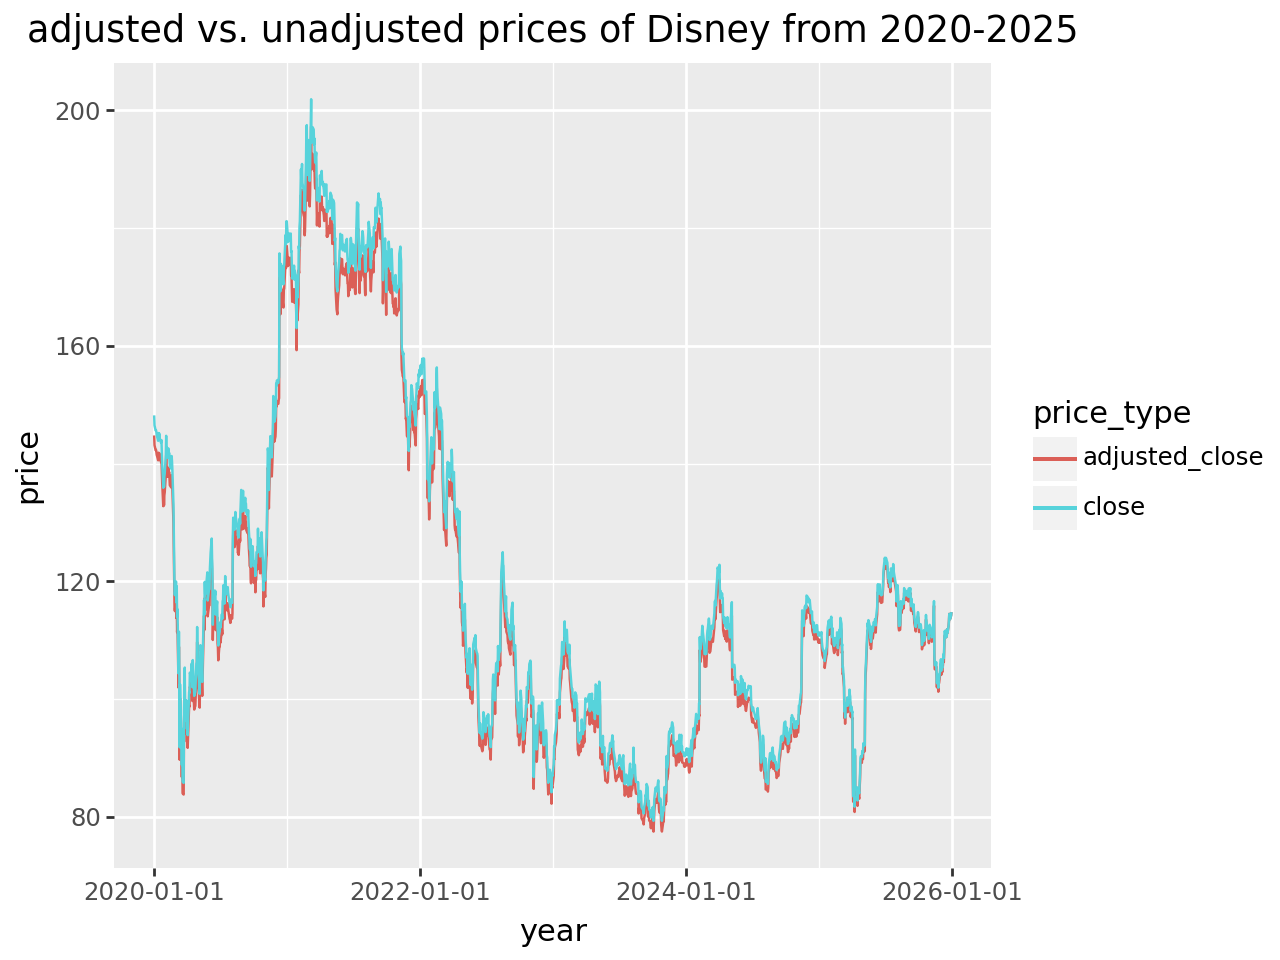

/usr/local/lib/python3.12/dist-packages/mizani/breaks.py:448: FutureWarning: Passing the width as the parameter has been deprecated and will not work in a future version. Use breaks_date(width="4 years")


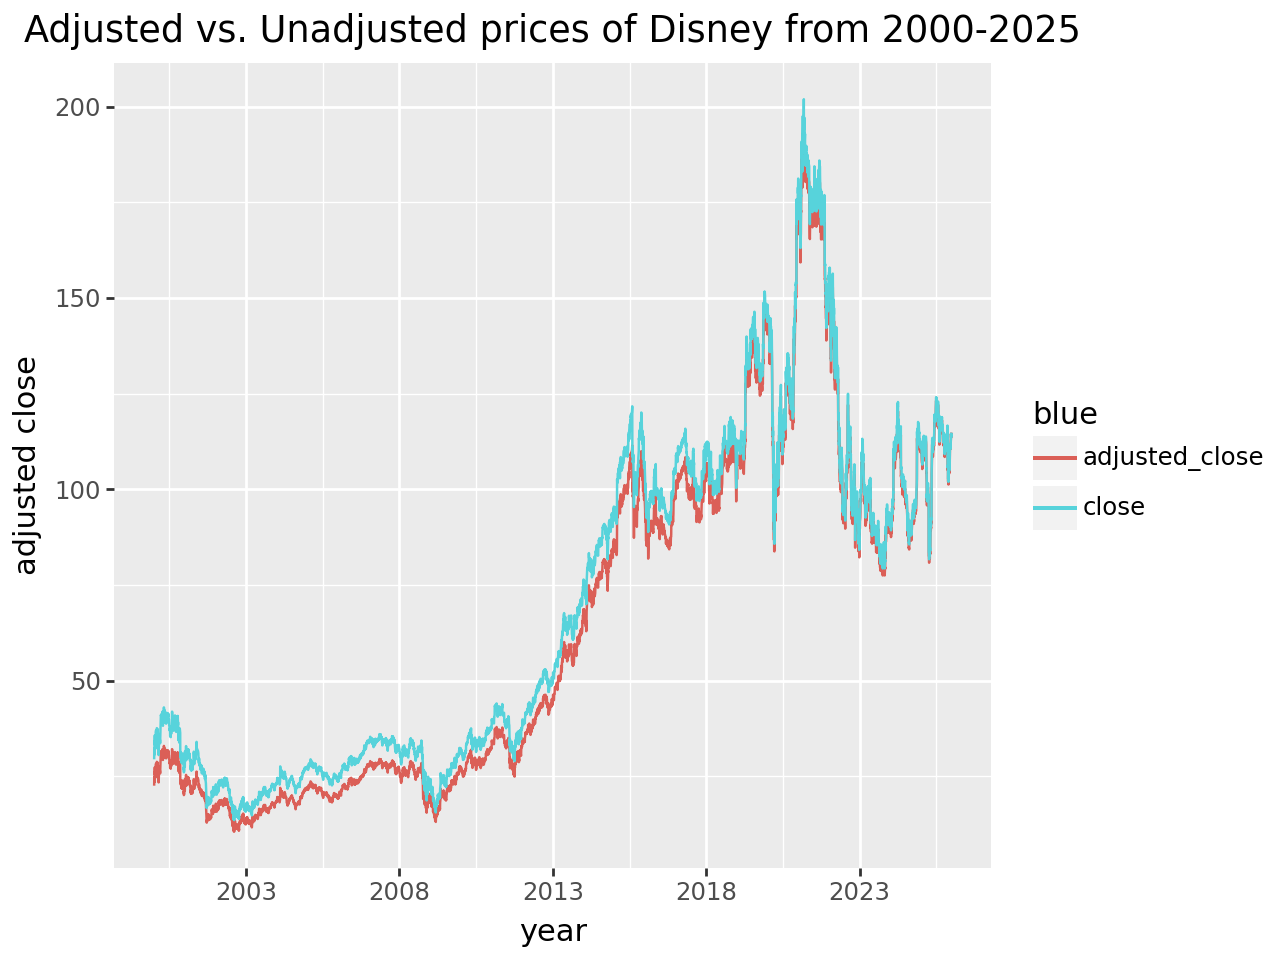

/usr/local/lib/python3.12/dist-packages/plotnine/layer.py:284: PlotnineWarning: stat_bin : Removed 1 rows containing non-finite values.


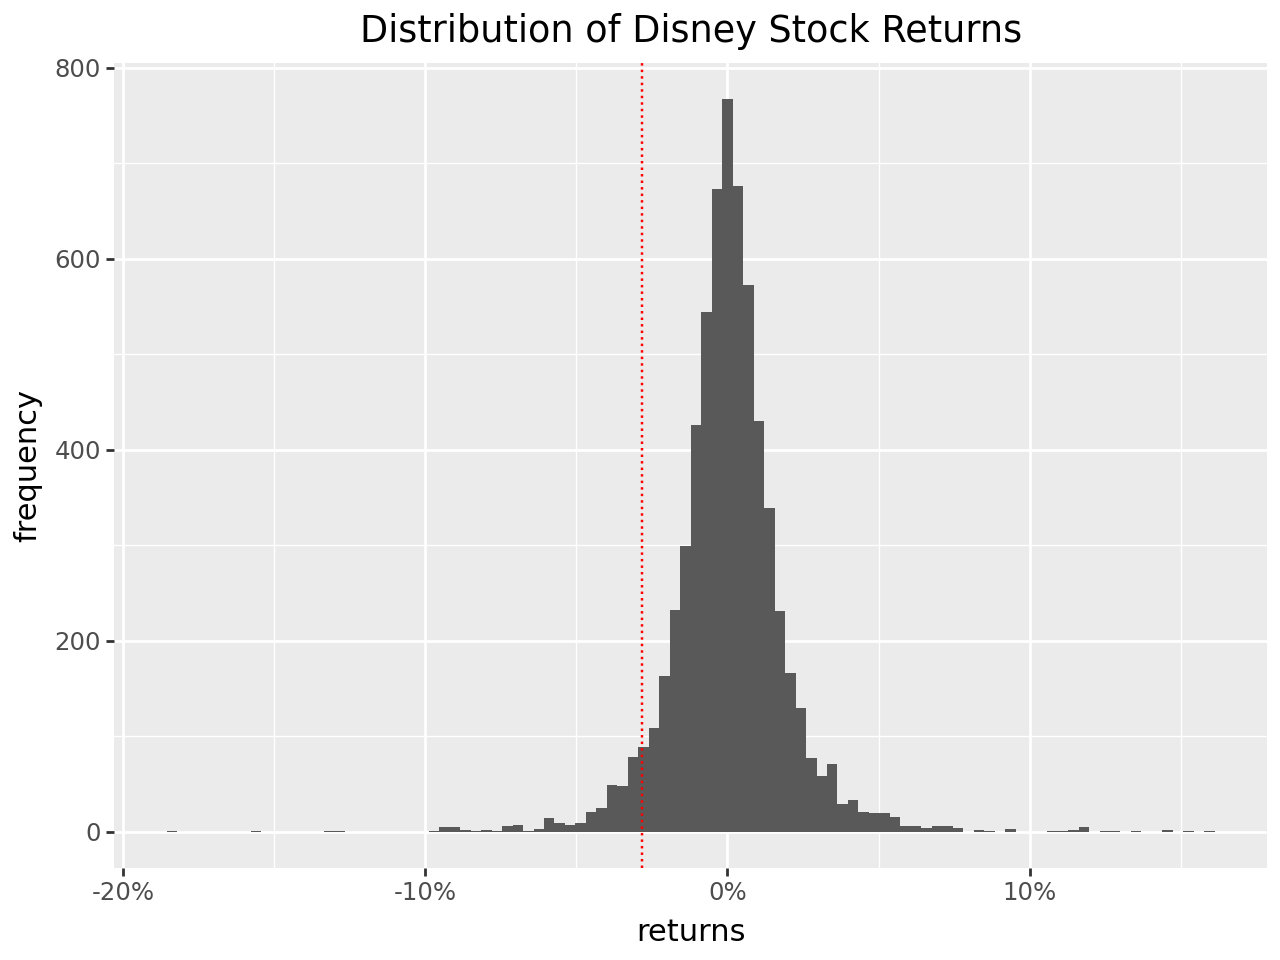

,count,mean,std,min,25%,50%,75%,max
date,,,,,,,,
2000,251.0,0.000,0.030,-0.156,-0.017,-0.002,0.017,0.153
2001,248.0,-0.001,0.029,-0.184,-0.016,-0.003,0.014,0.112
2002,252.0,-0.000,0.029,-0.090,-0.018,-0.002,0.020,0.084
2003,252.0,0.002,0.020,-0.072,-0.011,0.003,0.013,0.093
2004,252.0,0.001,0.016,-0.039,-0.008,0.000,0.008,0.146
2005,252.0,-0.000,0.011,-0.035,-0.008,-0.001,0.005,0.039
2006,251.0,0.002,0.012,-0.040,-0.005,0.001,0.008,0.070
2007,251.0,-0.000,0.013,-0.057,-0.007,0.001,0.008,0.036
2008,253.0,-0.001,0.031,-0.097,-0.014,-0.002,0.013,0.160


In [1]:
#come back to #4 later, and finish #5

!pip install tidyfinance

import sys
print(sys.version)

import pandas as pd
import numpy as np
import tidyfinance as tf

from plotnine import *

from mizani.formatters import percent_format

#1: download data for another stock and plot 2 time series of the symbol's unadjusted and adjusted closing prices

prices_short = tf.download_data(
    domain="stock_prices",
    symbols = 'DIS',
    start_date = '2020-01-01',
    end_date = '2025-12-31'
)

prices_short.head().round(3)

prices_short_combined = prices_short.melt(
    id_vars="date",
    value_vars=["adjusted_close", "close"],
    var_name="price_type",
    value_name="price"
)

prices_short_figure = (
    ggplot(prices_short_combined, aes(x="date", y="price", color="price_type"))
    + geom_line()
    + labs(x="year",y="price", title="adjusted vs. unadjusted prices of Disney from 2020-2025")
)

prices_short_figure.show()

prices_long = tf.download_data(
  domain = "stock_prices",
  symbols = "DIS",
  start_date = "2000-01-01",
  end_date = "2025-12-31"
 )

prices_long_combined = prices_long.melt(
    id_vars = "date",
    value_vars = ["adjusted_close", "close"],
    var_name = "price_type",
    value_name="price"
)

prices_long_figure = (
    ggplot(prices_long_combined, aes(x="date", y="price", color="price_type"))
    + geom_line()
    + scale_x_datetime(date_breaks="5 years", date_labels="%Y")
    + labs(
        x="year", y="adjusted close",
        title="Adjusted vs. Unadjusted prices of Disney from 2000-2025", color = "blue"
    )
)
prices_long_figure.show()

#The adjusted close always seems to be just slightly below the close. This makes
#sense as a large company like Disney might split shares to create more activity

#2: compute daily returns for and visualize the distribution of daily returns in
#a histogram with 100 bins. add the 5 percent quantile with a dotted, red line. compute summary statistics for the returns

daily_returns = (prices_long
    .sort_values("date")
    .assign(ret = lambda x: x["adjusted_close"].pct_change())
    .get(["symbol", "date", "ret"])
)

quantile_05 = daily_returns["ret"].quantile(0.05)

daily_returns_figure = (
    ggplot(daily_returns, aes(x="ret"))
    + geom_histogram(bins=100)
    + geom_vline(xintercept = quantile_05, linetype = "dotted", color = "red")
    + labs(x="returns", y='frequency', title="Distribution of Disney Stock Returns")
    + scale_x_continuous(labels=percent_format())
)
daily_returns_figure.show()

pd.DataFrame((daily_returns["ret"]).describe()).round(3).T

(daily_returns["ret"]
  .groupby(daily_returns['date'].dt.year)
  .describe()
  .round(3)
 )

In [ ]:
!pip install tidyfinance

import sys
print(sys.version)

import pandas as pd
import numpy as np
import tidyfinance as tf

from plotnine import *

from mizani.formatters import percent_format

#3 generate the above graphs/statistics for an arbitrary number of symbols

symbol = []
enter = ''

while enter != 'no':
  enter = input('Enter a symbol, or (no) to continue with calculations: ')
  if enter != 'no':
    symbol.append(enter)


print(symbol)

prices_daily = tf.download_data(
    domain = "stock_prices",
    symbols = symbol,
    start_date = '2000-01-01',
    end_date = '2025-12-31'
)

prices_daily_figure = (
    ggplot(prices_daily, aes(x="date", y="adjusted_close", color='symbol'))
    + geom_line()
    + scale_x_datetime(date_breaks="5 years", date_labels="%Y")
    + labs(x="Date", y="Adjusted Close", title=f"Adjusted Close of {', '.join(symbol)}")
)
prices_daily_figure.show()

returns = (prices_daily
    .sort_values(['date','symbol'])
    .assign(ret = lambda x: x.groupby('symbol')["adjusted_close"].pct_change())
    .get(['symbol', 'date', 'ret'])
)

quantile_05 = returns['ret'].quantile(0.05)

returns_figure = (
    ggplot(returns, aes(x="ret", fill="symbol"))
    + geom_histogram(position="identity", bins=100, alpha=0.5)
    + geom_vline(xintercept=quantile_05, linetype='dotted', color='red')
    + labs(x="Returns", y="Frequency", fill = 'symbol', title=f"Distribution of returns for {', '.join(symbol)}")
    + scale_x_continuous(labels=percent_format())
)
returns_figure.show()

(returns
  .assign(year = lambda x: x['date'].dt.to_period('5Y'))
  .groupby(['year','symbol'])['ret']
  .describe()
  .round(3)
)

3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]


In [ ]:
#5 Create a figure to visualize if days with high aggregate trading volume correspond with days of high aggregate returns

!pip install tidyfinance

import sys
print(sys.version)

import pandas as pd
import numpy as np
import tidyfinance as tf

from plotnine import *

from mizani.formatters import percent_format

#1: download data for another stock and plot 2 time series of the symbol's unadjusted and adjusted closing prices

prices_long = tf.download_data(
  domain = "stock_prices",
  symbols = "AAPL",
  start_date = "2000-01-01",
  end_date = "2025-12-31"
 )

daily_returns = (prices_long
    .sort_values("date")
    .assign(ret = lambda x: x["adjusted_close"].pct_change())
    .get(["symbol", "date", "ret",'volume','adjusted_close'])
)

trading_volume = (
    daily_returns
    .sort_values('date')
    .assign(total_volume = lambda x: x['adjusted_close']*x['volume']/1e9)
    .assign(abs_ret = lambda x: x['ret'].abs())
    .get(['date','total_volume','ret', 'abs_ret'])
)

adjusted_data = (
    trading_volume
    .sort_values('date')
    .assign(adjusted_volume = lambda x: (x['total_volume']-x['total_volume'].min())/(x['total_volume'].max()-x['total_volume'].min()))
    .assign(adjusted_returns = lambda x: (x['ret'].abs()-x['ret'].abs().min())/(x['ret'].abs().max()-x['ret'].abs().min()))
    .get(['date','adjusted_volume','adjusted_returns'])
)

comparison_figure = (
    ggplot(adjusted_data, aes(x='adjusted_volume', y='adjusted_returns'))
    + geom_point()
    + geom_abline(aes(intercept=0, slope=1), linetype = 'dashed')
    + labs(x='Daily Value Traded', y='Daily Abs. Returns', title='Daily Value Traded vs. Daily Abs. Returns for Apple 2000-2025')
)

correlation_value = trading_volume['total_volume'].corr(trading_volume['abs_ret'])
print(correlation_value)
comparison_figure.show()